In [ ]:
# Import necessary libraries for data manipulation and visualization

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure plots are displayed inline in the notebook
%matplotlib inline

In [ ]:
# Afterwards we load the CSV file that contains the dataset

# Load the Amazon UK dataset from CSV into a DataFrame
dataframe = pd.read_csv(r"amz_uk_price_prediction_dataset.csv")
dataframe = pd.DataFrame(dataframe) # Ensure it's a proper DataFrame object

# Create a backup copy of the original DataFrame
# This allows us to revert changes if any data manipulation goes wrong
backup_dataframe = dataframe.copy()


In [ ]:
# Separate numerical and categorical columns for easier analysis
# This allows us to apply numeric operations on numeric columns and categorical operations on text columns

numeric = dataframe.select_dtypes(include="number")
categorical = dataframe.select_dtypes(exclude="number")


# Display the first few rows to check the structure of the DataFrame
dataframe.head()





,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [ ]:

# Check possible missing values

missing_values = pd.isnull(dataframe)
# Count missing values in each column
missing_counts = missing_values.sum()

# Count columns with missing values
columns_with_missing = missing_counts[missing_counts > 0].count()

# Check if all columns have missing values
all_columns_missing = missing_counts.all()

# Calculate the total number of missing values
total_missing_values = missing_counts.sum()

# Display the results
print("Missing Values in Each Column:\n", missing_counts)
print("\nNumber of Columns with Missing Values:", columns_with_missing)
print("All Columns Have Missing Values:", all_columns_missing)
print("\nTotal Missing Values in the DataFrame:", total_missing_values)


   


Missing Values in Each Column:
 uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

Number of Columns with Missing Values: 0
All Columns Have Missing Values: False

Total Missing Values in the DataFrame: 0


In [ ]:
# In this case, there are no missing values, so we can proceed without data cleaning

# Calculate the absolute frequency of each product category
frequency_table = categorical["category"].value_counts()

# Calculate the relative frequency (proportion) of each category
proportion_table = categorical["category"].value_counts(normalize=True).round(2)

# Combine absolute and relative frequencies into a single DataFrame for easier analysis
second_dataframe = pd.concat([frequency_table, proportion_table], axis=1)
second_dataframe.columns = ['absolute_frequency', 'relative_frequency']

# Sort categories by absolute frequency in descending order to identify the most common categories
second_dataframe = second_dataframe.sort_values(by='absolute_frequency', ascending=False)

# Display the top 5 most listed categories
second_dataframe.head(5)

,absolute_frequency,relative_frequency
category,,
Sports & Outdoors,836265,0.34
Beauty,19312,0.01
"Handmade Clothing, Shoes & Accessories",19229,0.01
Bath & Body,19092,0.01
Birthday Gifts,18978,0.01


In [54]:
# Top categories identified from the output:
# - Sports & Outdoors
# - Beauty 
# - Handmade Clothing, Shoes & Accessories
# - Bath & Body
# - Birthday Gifts

# Filter the DataFrame to include only the top categories for visualization purposes
top_categories=["Sports & Outdoors","Beauty",
                "Handmade Clothing, Shoes & Accessories",
                "Bath & Body","Birthday Gifts"]

listed_top_categories = second_dataframe[ second_dataframe.index.isin(top_categories)] 

# Display the filtered DataFrame of top categories
print(listed_top_categories) 

                                        absolute_frequency  relative_frequency
category                                                                      
Sports & Outdoors                                   836265                0.34
Beauty                                               19312                0.01
Handmade Clothing, Shoes & Accessories               19229                0.01
Bath & Body                                          19092                0.01
Birthday Gifts                                       18978                0.01


## Analysis
### "The Sports & Outdoors category dominates the catalog with 20% of the products, followed by Beauty and Bath & Body. This indicates that Amazon UK customers have a great interest in sports and personal care items, while other categories represent a smaller proportion of the catalog.

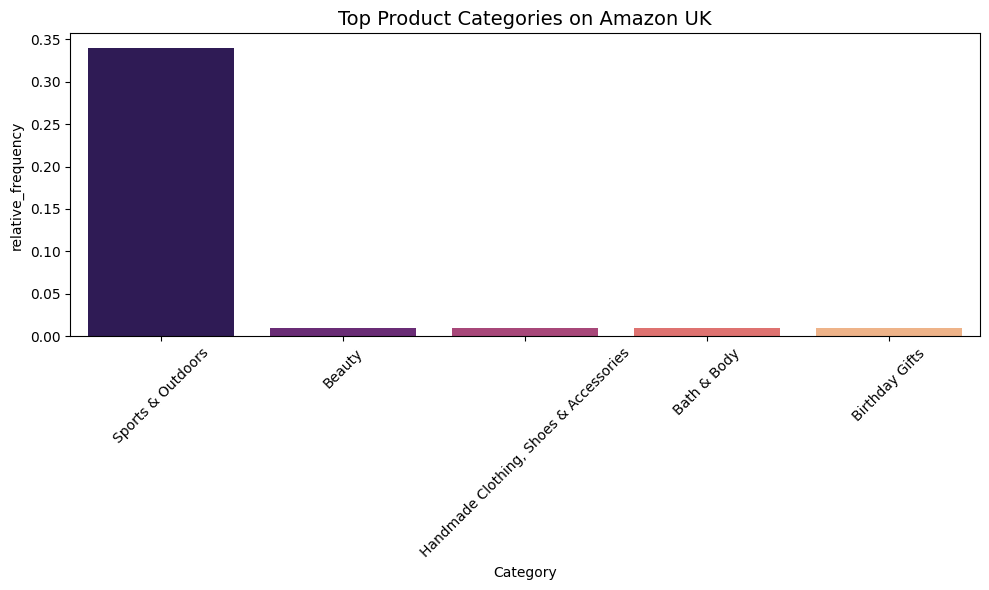

In [ ]:
# Bar Chart: Top Product Categories

# Set figure size for better readability
plt.figure(figsize=(10,6))

# Create a bar chart showing the relative frequency of top product categories
sns.barplot(
    x= "category",
    y="relative_frequency",
    data = listed_top_categories,
    palette ="magma",
    hue ="category",
    legend=False # Hide redundant legend
) 

# Add titles and labels
plt.title("Top Product Categories on Amazon UK", fontsize=14)
plt.xlabel("Category")
plt.xticks(rotation=45)    # Rotate x-axis labels for readability
plt.tight_layout()         # Adjust layout automatically


plt.show()

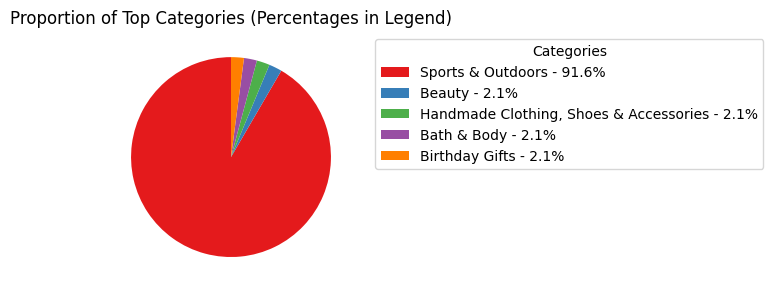

In [ ]:
# Pie Chart: Proportion of Top Categories

# Extract absolute frequencies for plotting
frequencies = listed_top_categories['absolute_frequency']

# Set color palette
plt.figure(figsize=(7,7))
colors = sns.color_palette("Set1", len(frequencies))

# Create pie chart without labels (will add legend instead)
plt.pie(frequencies, labels=None, startangle=90, colors=colors)

# Calculate total for percentages
total= frequencies.sum()


# Prepare custom legend showing category name and percentage
labels=[]

for cate, freq in zip(frequencies.index,frequencies):
    percent = freq / total * 100
    labels.append(f"{cate} - {percent:.1f}%")

# Add title and adjust layout
plt.legend(labels, title="Categories", bbox_to_anchor=(1.05,1),loc = "upper left")
plt.title("Proportion of Top Categories (Percentages in Legend)")
plt.tight_layout()

plt.show()




In [ ]:

# Numerical part

display(numeric["price"].describe())


numeric_mean = numeric["price"].mean()
numeric_mode = numeric["price"].mode().iloc[0]
numeric_median = numeric["price"].median()

print(f"-The mean for the price column is: {numeric_mean:.2f}")
print(f"-The mode for the price column is: {numeric_mode}")
print(f"- The median for the price column is: {numeric_median}")


count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

-The mean for the price column is: 89.24
-The mode for the price column is: 9.99
- The median for the price column is: 19.09


## Analysis:
The mean is much greater than the median and mode, 
#indicating that extremely high prices raise the mean.
#Most products have low prices, typically between £10–20.

In [61]:

# Measures of Dispersion for Product Prices

# Calculate variance: measure of how spread out the prices are
numeric_variance = numeric["price"].var()

# Calculate standard deviation: typical distance of prices from the mean
numeric_stdeviation = numeric["price"].std()

# Calculate the total price range (max - min)
price_range = numeric['price'].max() - numeric['price'].min()

# Calculate Interquartile Range (IQR = Q3 - Q1) 
# Represents the middle 50% of the data, less affected by outliers
IQR = numeric['price'].describe()['75%'] - numeric['price'].describe()['25%']


# Print dispersion metrics
print(f"Range: £{numeric['price'].min()} - £{numeric['price'].max()} (total {price_range})")
print(f"Variance: {numeric_variance:.2f}")
print(f"Standard Deviation: {numeric_stdeviation:.2f}")
print(f"Interquartile Range (IQR): £{IQR:.2f}")


# Displaying the analysis of Price Dispersion
print("\nAnalysis:")
print("Most products are concentrated in the IQR range, indicating a moderate spread around the median price.")
print("The full price range is larger due to some extreme high or low prices (outliers).")
print("Overall, prices are moderately dispersed, with the majority clustering near typical price points.")


Range: £0.0 - £100000.0 (total 100000.0)
Variance: 119445.49
Standard Deviation: 345.61
Interquartile Range (IQR): £36.00

Analysis:
Most products are concentrated in the IQR range, indicating a moderate spread around the median price.
The full price range is larger due to some extreme high or low prices (outliers).
Overall, prices are moderately dispersed, with the majority clustering near typical price points.


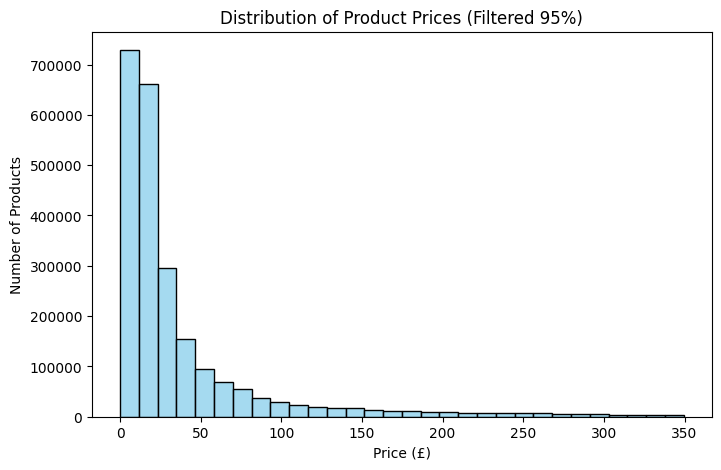

In [62]:

# Histogram: Distribution of Product Prices


# To avoid distortion from extreme outliers, filter prices at the 95th percentile
upper_limit = numeric['price'].quantile(0.95)
prices_filtered = numeric[numeric['price'] <= upper_limit]['price']


# Plot histogram to visualize where most products' prices fall
plt.figure(figsize=(8,5))
sns.histplot(prices_filtered, bins=30, color='skyblue')
plt.title("Distribution of Product Prices (Filtered 95%)")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.show()


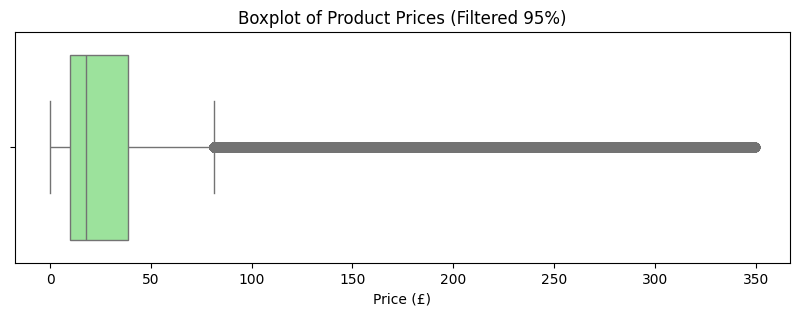

In [60]:
# Boxplot: Spread and Outliers of Product Prices

#Plot a boxplot to visualize the distribution and identify potential outliers
# Using the filtered data (95th percentile) to avoid extreme values distorting the plot

plt.figure(figsize=(10,3))
sns.boxplot(x=prices_filtered, color='lightgreen')
plt.title("Boxplot of Product Prices (Filtered 95%)")

# Add title and axis label
plt.xlabel("Price (£)")
plt.show()


## Analysis:
Most products on Amazon UK are concentrated at low prices, typically between £10–20. Some extremely expensive products raise the mean and standard deviation, but do not represent the general trend. The interquartile range reflects that the central 50% of products have relatively close prices, while the outliers are exceptions.

In [ ]:
# Descriptive Statistics for Product Ratings

# Display basic descriptive statistics for the 'stars' column
dataframe.stars.describe()

# Calculate central tendency measures for ratings
numeric_mode_stars = numeric["stars"].mode().iloc[0]   # Most frequent rating
numeric_mean_stars = numeric["stars"].mean()           # Average rating
numeric_median_stars = numeric["stars"].median()       # Median rating


# Print results
print(f"-The mean for the stars column is: {numeric_mean_stars:.2f}")
print(f"-The mode for the stars column is: {numeric_mode_stars}")
print(f"- The median for the stars column is: {numeric_median_stars}")


# Interpretation

# The most repeated value (mode) and median are both 0,
# likely because many products have not yet received reviews.
# This suggests a large portion of products have no ratings initially.

-The mean for the stars column is: 2.15
-The mode for the stars column is: 0.0
- The median for the stars column is: 0.0


In [ ]:
# Measures of Dispersion for Product Ratings

# Calculate variance: measures how spread out the ratings are
numeric_variance_stars = numeric["stars"].var()

# Calculate standard deviation: typical deviation from the mean rating
numeric_stdeviation_stars = numeric["stars"].std()


# Calculate Interquartile Range (IQR = Q3 - Q1) 
# Represents the middle 50% of ratings
IQR_stars = numeric['stars'].describe()['75%'] - numeric['stars'].describe()['25%']

# Print dispersion metrics
print(f"Variance: {numeric_variance_stars:.2f}")
print(f"Standard Deviation: {numeric_stdeviation_stars:.2f}")
print(f"Interquartile Range (IQR): {IQR_stars:.2f}")

# Interpretation

# The variance and IQR are relatively small, indicating that most ratings are very similar.
# This suggests that there are few extreme ratings (outliers), and the majority of products have low or zero ratings.

Variance: 4.82
Standard Deviation: 2.19
Interquartile Range (IQR): £4.40


In [ ]:
# Shape of the Distribution: Skewness and Kurtosis


# Calculate skewness: measures the asymmetry of the ratings distribution
skewness_stars = round(float(numeric["stars"].skew()), 2)

# Calculate kurtosis: measures the "tailedness" of the distribution

# Excess kurtosis = 0 corresponds to a normal distribution
kurtosis_stars = numeric['stars'].kurtosis()  

# Print skewness and kurtosis values
print(f"The skewness for the stars column is: {skewness_stars}")
print(f"The kurtosis for the stars column is: {kurtosis_stars:.2f}")

# Interpretation based on skewness
if skewness_stars == 0:
    print(" The distribution is perfectly symmetrical, resembling a normal distribution.")
elif skewness_stars > 0:
    print("""The distribution is **positively skewed** (right-skewed).
     - Longer tail on the **right** side.  
     - The bulk of the data is concentrated on the **left**.""")
elif skewness_stars < 0:
    print(""" The distribution is **negatively skewed** (left-skewed).  
        - Longer tail on the **left** side.  
        - The bulk of the data is concentrated on the **right**.""")
        
# Note:
# - Positive skew means most products have low ratings, with few high ratings.
# - Negative skew would indicate most products have high ratings, with few low ratings.
# - Kurtosis indicates how heavy or light the tails are compared to a normal distribution.


The skewness for the stars column is: 0.08
The kurtosis for the stars column is: -1.93
The distribution is **positively skewed** (right-skewed).
     - Longer tail on the **right** side.  
     - The bulk of the data is concentrated on the **left**.


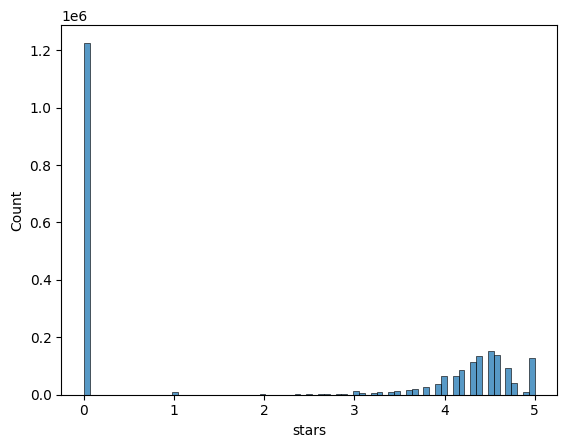

In [50]:
sns.histplot(numeric["stars"], bins="auto")
plt.show()


## Analysis:

Most products have a rating of 0, meaning they have not yet been reviewed. Among products that have ratings, the distribution is slightly right-skewed (skewness = 0.08) and relatively flat (kurtosis = -1.93). Ratings are mostly concentrated between 4 and 5 stars, with few products receiving low ratings, indicating that reviewed products tend to be positively rated.